Cleaning Data to only Include Students in all 3 Networks

In [56]:
# import necessary packages
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

In [57]:
# import the self-reported friendship data
df_friendships = pl.read_csv("/Users/maggiebothwell/Documents/GitHub/Project-Repository/Data/Raw/Friendship-network_data_2013.csv", 
    separator=" ",
    has_header=False,
    new_columns=["i", "j"])

# import the contact diary data
df_contact_diary = pl.read_csv("/Users/maggiebothwell/Documents/GitHub/Project-Repository/Data/Raw/Contact-diaries-network_data_2013.csv", 
    separator=" ",
    has_header=False,
    new_columns=["i", "j", "w"])

# import the sensor data information 
sensor_data = pl.read_csv("/Users/maggiebothwell/Documents/GitHub/Project-Repository/Data/Raw/HighSchool2013_proximity_net.csv",
    separator=" ",
    has_header=False,
    new_columns=["t", "i", "j", "Ci", "Cj"],
)
# drop the columns that contain the class information of each student, as this is not relevant to our research
sensor_data = sensor_data.drop(["Ci", "Cj"])

In [58]:
# turn the friendship data into a list of unique students, by combining the students in columns "i" and "j", and select
# each student only once
unique_friendship = pl.concat([df_friendships["i"], df_friendships["j"]]).unique()

# turn the contact diary data into a list of unique students, by combining the students in columns "i" and "j", and select
# each student only once
unique_contact_diary = pl.concat([df_contact_diary["i"], df_contact_diary["j"]]).unique()

# turn the sensor data into a list of unique students, by combining the students in columns "i" and "j", and select
# each student only once
unique_sensor = pl.concat([sensor_data["i"], sensor_data["j"]]).unique()

len(unique_friendship) # 134 students
len(unique_contact_diary) # 120 students
len(unique_sensor) # 327 students

# create a list of the students that are present in all three datasets

# find the students that are shared between the friendship and contact diary datasets
friendship_contact_shared = unique_friendship.filter(unique_friendship.is_in(unique_contact_diary.to_list()))

# now find the students who are also present in the sensor data
shared_students = friendship_contact_shared.filter(friendship_contact_shared.is_in(unique_sensor.to_list())).to_list()
len(shared_students) # 69 students are present in all three data sets

69

In [59]:
# this saves only the interactions in the friendship network that have interactions between both students present in all three datasets
friendships_filtered = df_friendships.filter(pl.col("i").is_in(shared_students) & pl.col("j").is_in(shared_students))

# this saves only the interactions in the contact diary network that have interactions between both students present in all three datasets
diary_filtered = df_contact_diary.filter(pl.col("i").is_in(shared_students) & pl.col("j").is_in(shared_students))

# this saves only the interactions in the sensor network that have interactions between both students present in all three datasets
sensor_filtered = sensor_data.filter(pl.col("i").is_in(shared_students)& pl.col("j").is_in(shared_students))

Create the Networks for Each Dataset that Only Features the Shared 69 Students - FRIENDSHIP

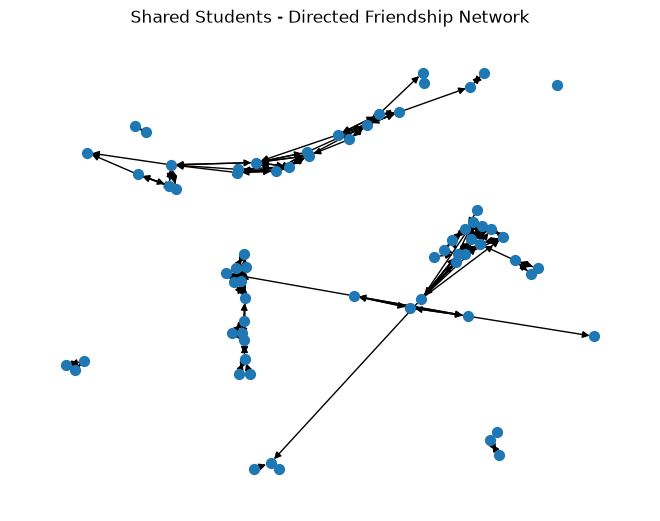

In [60]:
# create a directed network from the friendship data 
G_friendship_shared = nx.from_pandas_edgelist(friendships_filtered, "i", "j", create_using=nx.DiGraph())
G_friendship_shared.add_nodes_from(shared_students)

# view the graph and give it a title
nx.draw(G_friendship_shared, node_size =50)
plt.title("Shared Students - Directed Friendship Network")
plt.show()

In [61]:
import pickle
from pathlib import Path

# this code is used to save the shared friendship networks to a pickle file, which can then be retrieved in another notebook within the repository
save_path = Path("../Data/Cleaned/shared_students_friendship_network.pkl")

with save_path.open("wb") as file:
    pickle.dump(G_friendship_shared, file)

Create the Networks for Each Dataset that Only Features the Shared 69 Students - CONTACT DIARY

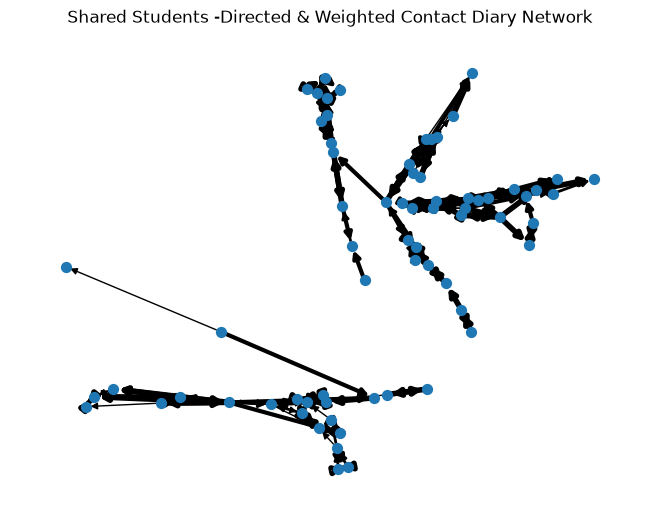

In [62]:
# create a weighted directed network from the contact diary data 
G_contact_diary_shared = nx.from_pandas_edgelist(diary_filtered, "i", "j", edge_attr="w", create_using=nx.DiGraph())

# view the graph, including edge weights as line widths - thicker edges represent a longer reported time of contact 
nx.draw(G_contact_diary_shared, node_size =50, width=list(nx.get_edge_attributes(G_contact_diary_shared, "w").values()))

plt.title("Shared Students -Directed & Weighted Contact Diary Network")
plt.show()

In [63]:
import pickle
from pathlib import Path

# this code is used to save the shared contact diary network to a pickle file, which can then be retrieved in another notebook within the repository
save_path = Path("../Data/Cleaned/shared_students_contact_diary_network.pkl")

with save_path.open("wb") as file:
    pickle.dump(G_contact_diary_shared, file)

Create the Networks for Each Dataset that Only Features the Shared 69 Students - TEMPORAL

Using the exact same code from 11-09-2026_code002.ipynb to create a temporal network, but beginning with sensor_filtered 

In [64]:
# Store a list of all unique timestamps in chronological order
timestamps = sensor_filtered["t"].unique().sort()

# Start an empty dictionary which will store the interactions that occur for each time stamp
interactions_by_time = {}

# for each entry in the list of unique timestamps, filter the interactions dataframe to get only the 
# interactions that occur at that timestamp and save this in the dictionary 
for timestamp in timestamps:
    # at the timestamp of the current iteration of the loop, select only the rows that 
    # satisfy the condition that the timestamp column matches the current timestamp of the loop,
    # and store the filtered dataframe in the dictionary with the timestamp as the key
    interactions_by_time[timestamp] = sensor_filtered.filter(pl.col("t") == timestamp)

# verify the dictionary was correctly created with interactions grouped by timestamp
print(interactions_by_time)

{1385982020: shape: (5, 3)
┌────────────┬─────┬─────┐
│ t          ┆ i   ┆ j   │
│ ---        ┆ --- ┆ --- │
│ i64        ┆ i64 ┆ i64 │
╞════════════╪═════╪═════╡
│ 1385982020 ┆ 255 ┆ 275 │
│ 1385982020 ┆ 151 ┆ 866 │
│ 1385982020 ┆ 101 ┆ 425 │
│ 1385982020 ┆ 265 ┆ 494 │
│ 1385982020 ┆ 122 ┆ 255 │
└────────────┴─────┴─────┘, 1385982040: shape: (5, 3)
┌────────────┬──────┬──────┐
│ t          ┆ i    ┆ j    │
│ ---        ┆ ---  ┆ ---  │
│ i64        ┆ i64  ┆ i64  │
╞════════════╪══════╪══════╡
│ 1385982040 ┆ 101  ┆ 425  │
│ 1385982040 ┆ 265  ┆ 494  │
│ 1385982040 ┆ 577  ┆ 634  │
│ 1385982040 ┆ 1332 ┆ 1401 │
│ 1385982040 ┆ 122  ┆ 255  │
└────────────┴──────┴──────┘, 1385982060: shape: (6, 3)
┌────────────┬─────┬─────┐
│ t          ┆ i   ┆ j   │
│ ---        ┆ --- ┆ --- │
│ i64        ┆ i64 ┆ i64 │
╞════════════╪═════╪═════╡
│ 1385982060 ┆ 151 ┆ 866 │
│ 1385982060 ┆ 101 ┆ 425 │
│ 1385982060 ┆ 691 ┆ 869 │
│ 1385982060 ┆ 265 ┆ 494 │
│ 1385982060 ┆ 577 ┆ 634 │
│ 1385982060 ┆ 122 ┆ 255 │
└─────

In [65]:
# loop for every timestamp to create a network for each timestamp

# create an empty dictionary to store the networks for each timestamp
shared_temporal = {}

# for each timestamp that is in the list of unique timestamps, iterate over the following loop: 
for timestamp in timestamps:
    # select only the interactions that occurred at the current timestamp of the loop
    interactions_at_timestamp = interactions_by_time[timestamp]
    # create a network for the interactions at the current timestamp
    G_at_timestamp = nx.from_pandas_edgelist(interactions_at_timestamp, "i", "j")
    # save this network in the dictionary of shared temporal networks, where the key is the timestamp and the value is the network
    shared_temporal[timestamp] = G_at_timestamp


In [66]:
import pickle
from pathlib import Path

# this code is used to save the temporal networks to a pickle file, which can then be retrieved in another notebook within the repository
save_path = Path("../Data/Cleaned/shared_temporal_networks.pkl")
with save_path.open("wb") as file:
    pickle.dump(shared_temporal, file)